In [22]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf

import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_deep_learning as udl

import discriminator as Discriminator
import generator as Generator
# import feature_extractor as feature_extractor

tf.keras.backend.set_image_data_format("channels_first")


pil.SERVER = True

In [23]:
input_shape = (192,224,192)

G = Generator.create_generator_model(input_shape)

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator=G)
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))



In [24]:
def save_image(id, img_gen, img_path_name):
    _, affine = pil.load_preprocessed_image(3, id, absolute=True)
    pil.save_image(img_gen.astype(np.float32), affine, img_path_name)

def generate_image(id, G):   
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen = G(udl.prepare_img_for_gan(img_hunt3, axis_channels=1), training=False)
    img_gen = udl.recover_img_from_gan(img_gen, axis_channels=1)
    return img_hunt3, img_hunt4, img_gen


2024-04-04 00:18:46.580244: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-04-04 00:18:50.489412: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-04 00:18:58.293049: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


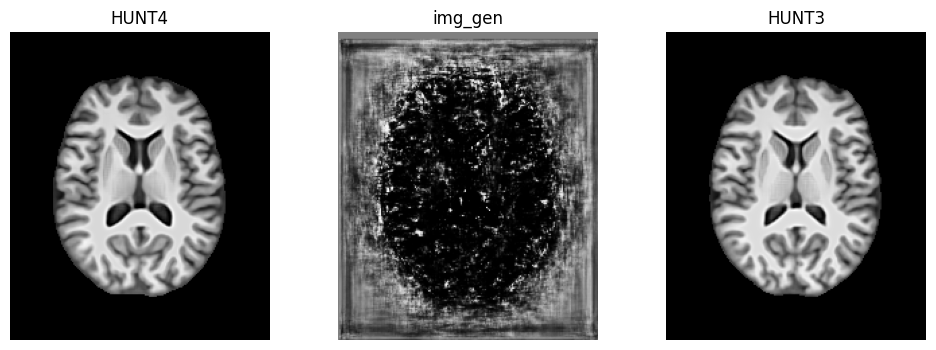

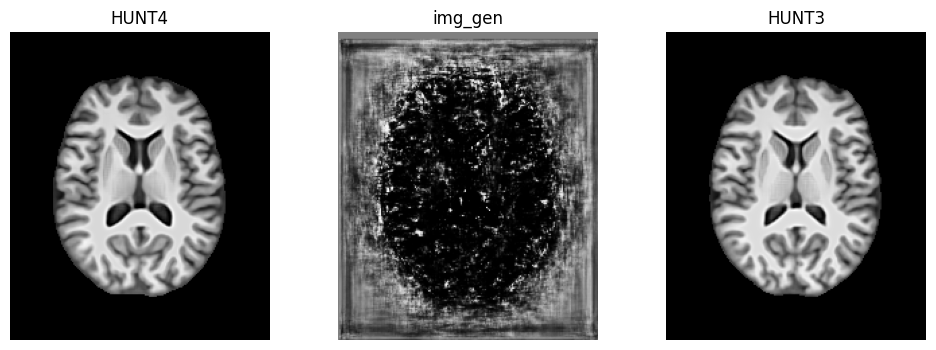

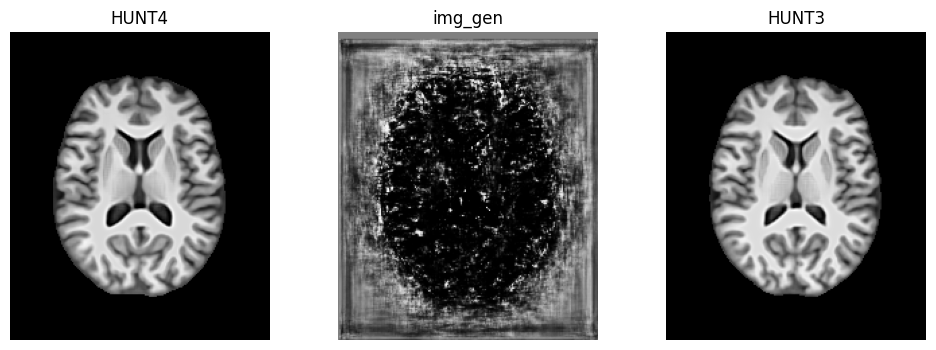

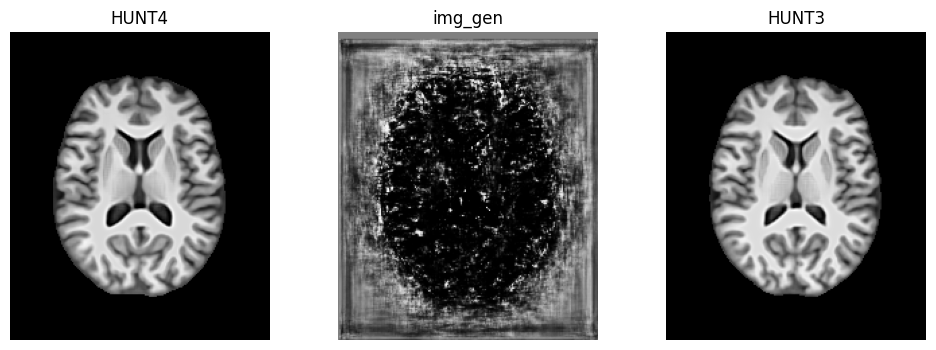

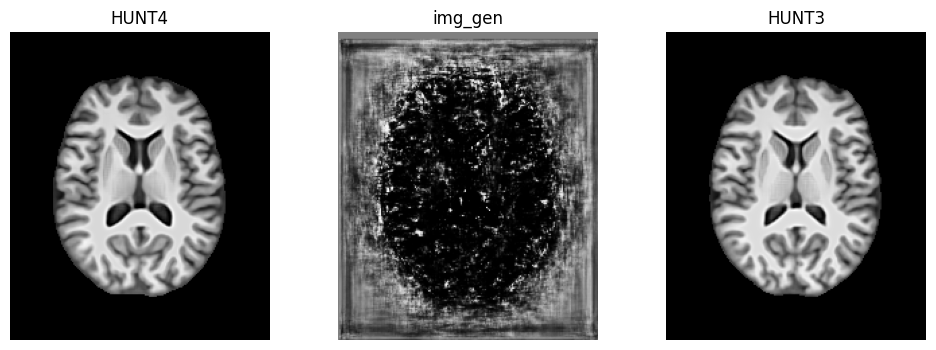

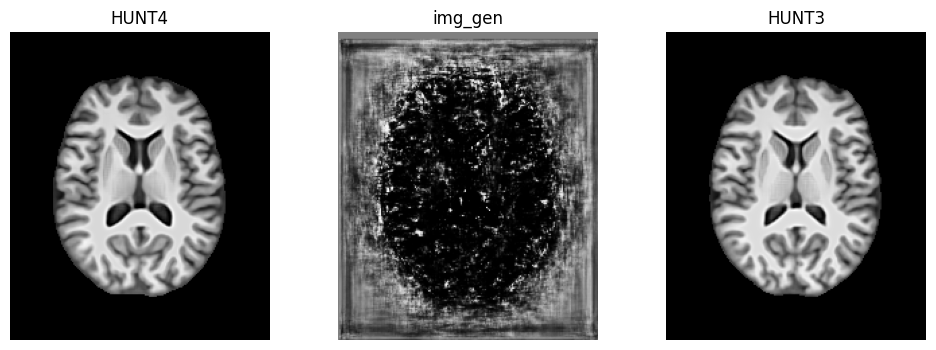

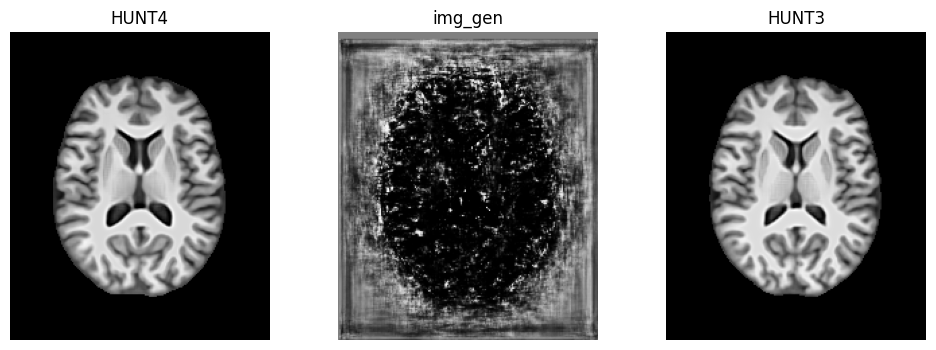

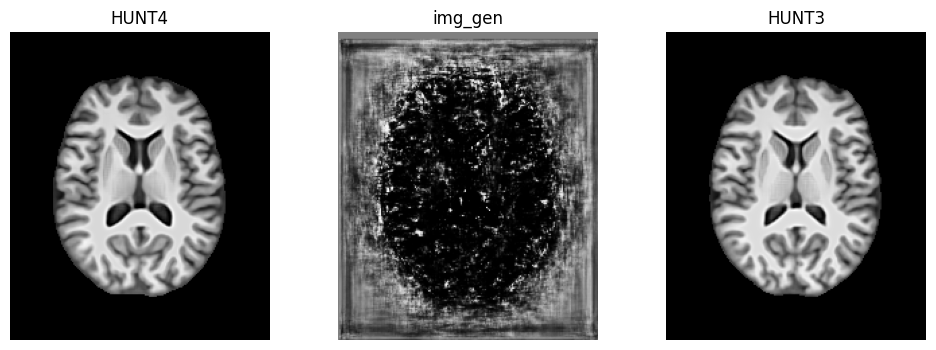

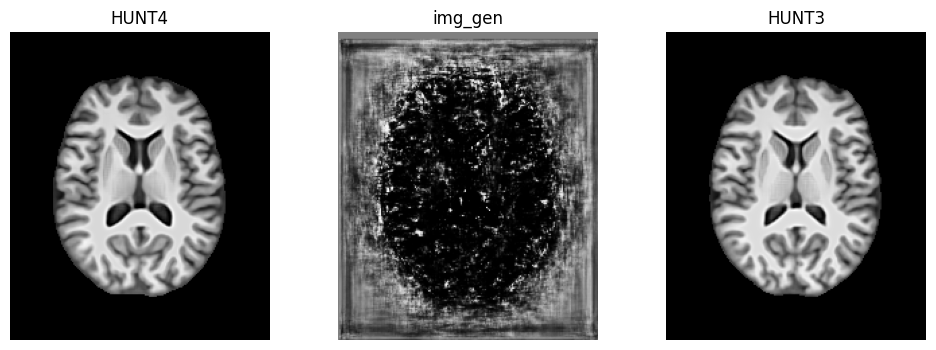

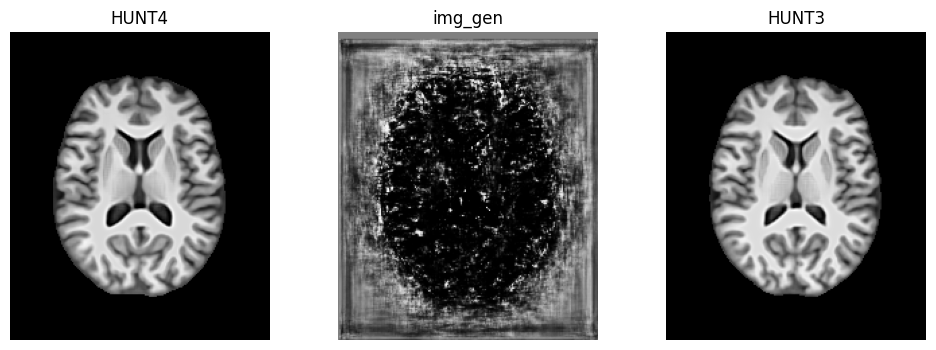

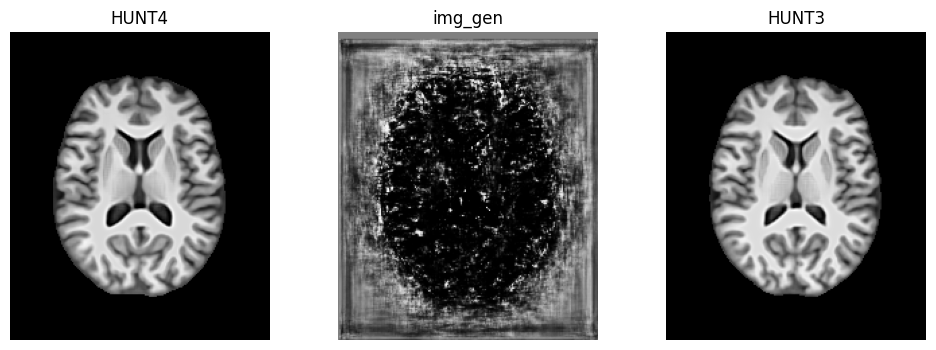

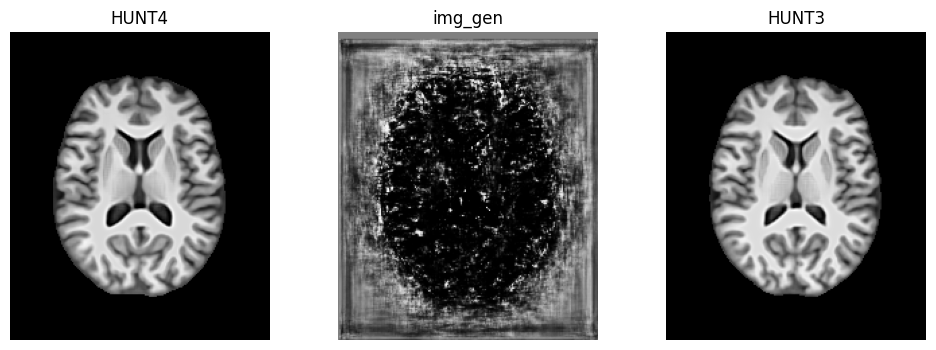

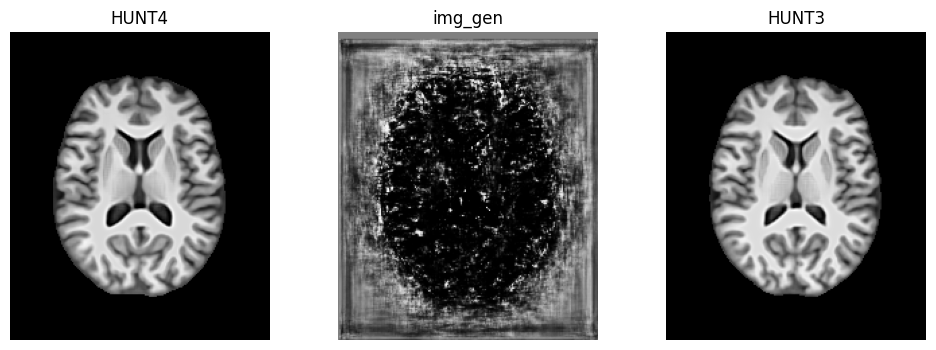

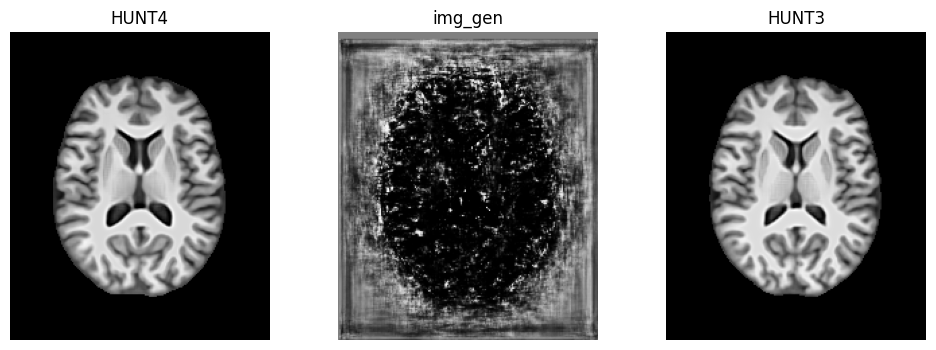

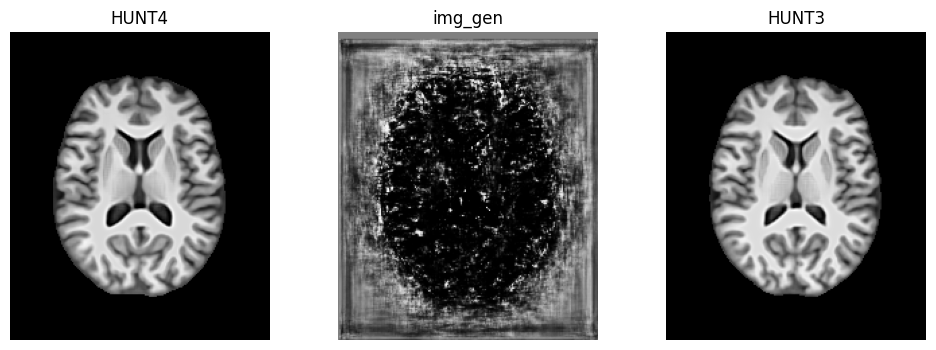

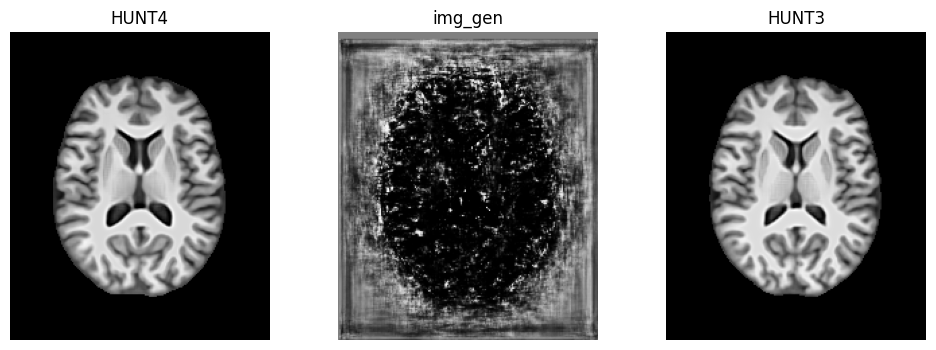

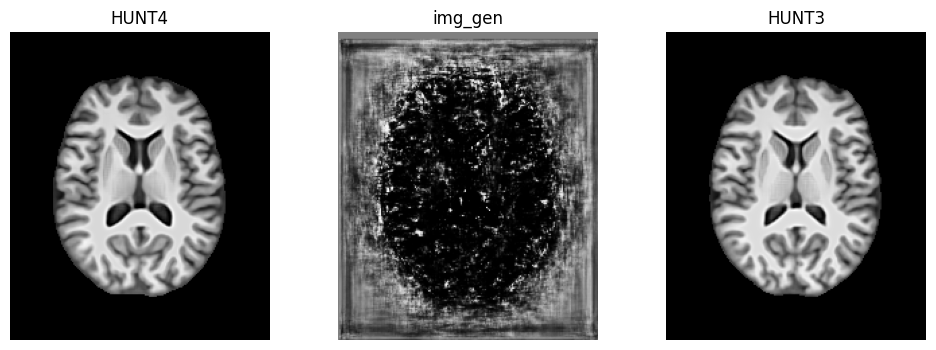

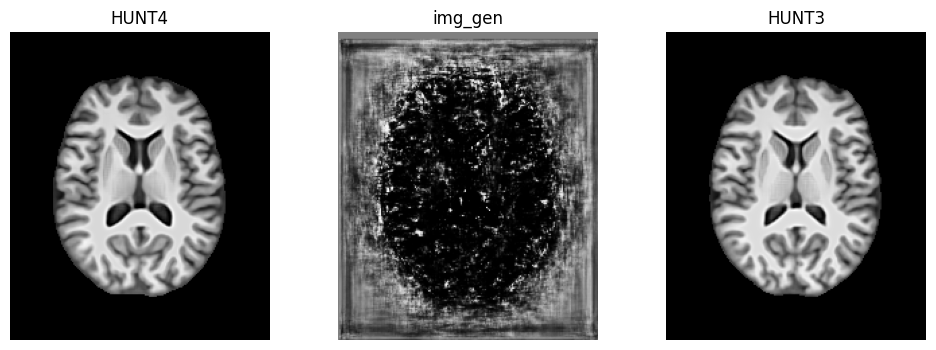

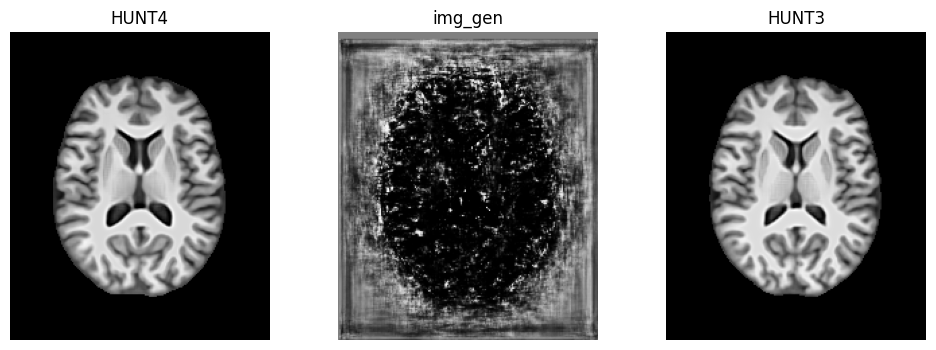

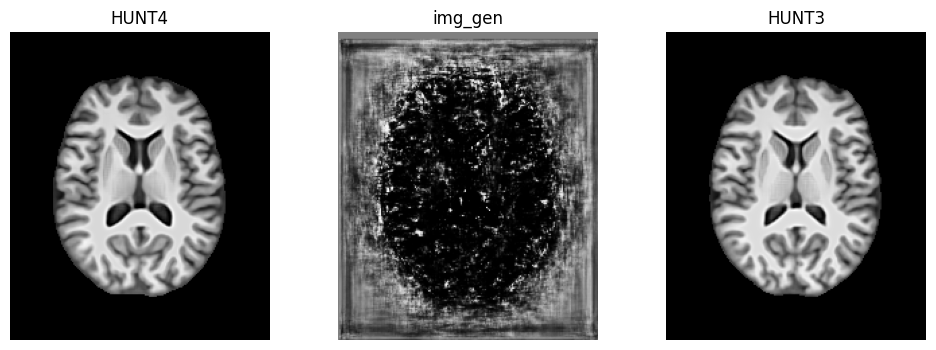

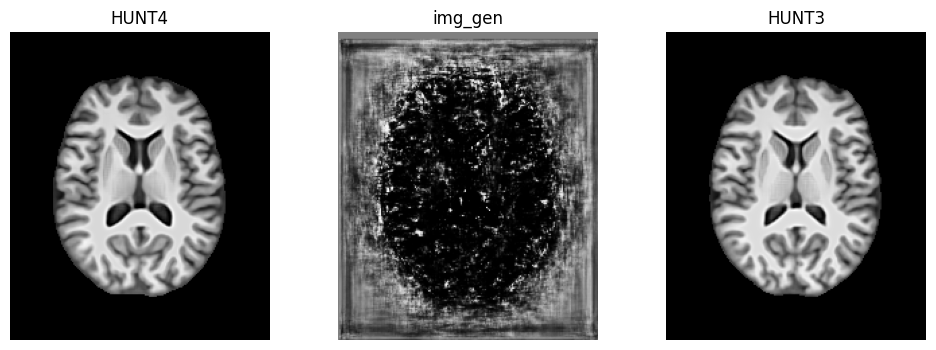

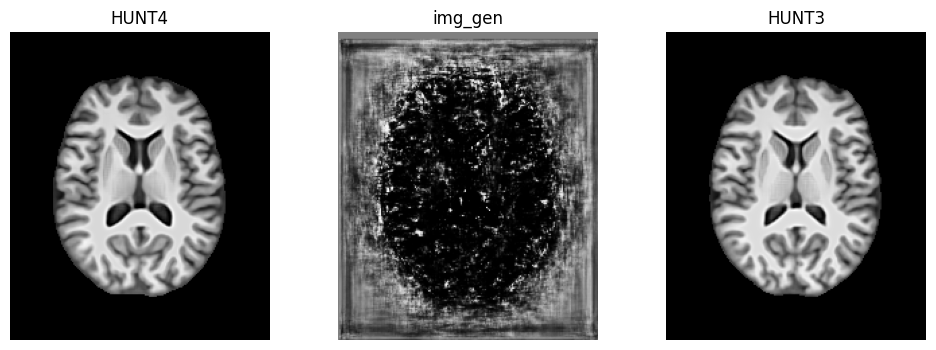

In [19]:
current_plane = 116

matching_ids = pil.get_matching_ids()
id_indexs = [302]
images_list = []
for checkpoint_index in range(1, 23, 1):
    print(f"-------- Checkpoint: {checkpoint_index}")
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
    for id_index in id_indexs:
        print(f"ID: {id_index}")
        id = matching_ids[id_index]

        img_hunt3, img_hunt4, img_gen = generate_image(id, G)
        vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=current_plane)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")

        # save image
        # img_path_name = f"{current_path}/images/first_results/{id}_CHECK_{checkpoint_index}.nii.gz"
        # save_image(id, img_gen, checkpoint_index)

